# Etapa 8 — Gráficos finais e tabela-resumo

Nada é reestimado aqui: o notebook só **lê os arquivos salvos** pelas etapas 4 a 7 e monta
os gráficos finais (PNG em `resultados/figuras/`) e a tabela-resumo (`resultados/resumo.xlsx`).

Convenção de cores em **todos** os gráficos: **azul = externo**, **laranja = doméstico**,
**cinza = não explicado / próprio do câmbio**.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RES = Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Cores (paleta validada para daltonismo) e tinta de texto
AZUL, LARANJA = "#2a78d6", "#eb6834"
CINZA_CLARO, CINZA_MEDIO = "#e1e0d9", "#a3a29b"
TINTA, TINTA_2, MUDO = "#0b0b0b", "#52514e", "#898781"
FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUDO, "ytick.color": MUDO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.labelcolor": TINTA_2,
})

def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [2]:
# Resultados das etapas anteriores
decomp_r2 = pd.read_csv(RES / "etapa5_decomposicao_r2.csv", index_col=0)          # etapas 4 e 5
fevd_bloco = pd.read_csv(RES / "etapa6_fevd_cambio_por_bloco.csv", index_col=0)    # VAR, por bloco
fevd_var = pd.read_csv(RES / "etapa6_fevd_cambio_por_variavel.csv", index_col=0)   # VAR, por variável
var60 = pd.read_csv(RES / "etapa7_var_janela60.csv", index_col=0, parse_dates=True)
var84 = pd.read_csv(RES / "etapa7_var_janela84.csv", index_col=0, parse_dates=True)
reg60 = pd.read_csv(RES / "etapa7_regressao_janela60.csv", index_col=0, parse_dates=True)

variacoes = pd.read_csv("dados/tratados/variacoes_mensais.csv", index_col=0, parse_dates=True)
limpas = pd.read_csv("dados/tratados/domesticas_limpas.csv", index_col=0, parse_dates=True)

## Painel A — amostra completa, por método

Tudo em **fração da variação total do câmbio** (soma = 1).

In [3]:
e4, e5 = decomp_r2["Etapa 4 (CDS original)"], decomp_r2["Etapa 5 (domésticas limpas)"]

painel_a = pd.DataFrame({
    "Regressão (etapa 4)":        {"externo": e4["só externo"], "sobreposição": e4["sobreposição"],
                                   "doméstico": e4["só doméstico"], "não explicado": 1 - e4["total"]},
    "Regressão limpa (etapa 5)":  {"externo": e5["só externo"], "sobreposição": 0.0,
                                   "doméstico": e5["só doméstico"], "não explicado": 1 - e5["total"]},
    "VAR, h = 1 (etapa 6)":       {"externo": fevd_bloco.loc["h=1", "externo"], "sobreposição": 0.0,
                                   "doméstico": fevd_bloco.loc["h=1", "doméstico"],
                                   "não explicado": fevd_bloco.loc["h=1", "próprio do câmbio"]},
    "VAR, h = 12 (etapa 6)":      {"externo": fevd_bloco.loc["h=12", "externo"], "sobreposição": 0.0,
                                   "doméstico": fevd_bloco.loc["h=12", "doméstico"],
                                   "não explicado": fevd_bloco.loc["h=12", "próprio do câmbio"]},
}).T
painel_a["externo / explicado"] = painel_a["externo"] / (painel_a["externo"] + painel_a["doméstico"])
painel_a.loc["Regressão (etapa 4)", "externo / explicado"] = float("nan")   # indefinido: há sobreposição sem dono
painel_a.round(3)

,externo,sobreposição,doméstico,não explicado,externo / explicado
Regressão (etapa 4),0.068,0.305,0.215,0.412,NaN
Regressão limpa (etapa 5),0.373,0.000,0.215,0.412,0.634
"VAR, h = 1 (etapa 6)",0.386,0.000,0.222,0.392,0.635
"VAR, h = 12 (etapa 6)",0.384,0.000,0.224,0.392,0.632


## Gráfico 1 — Os métodos concordam quando a sobreposição é atribuída

A barra de cima (etapa 4) tem uma faixa hachurada **sem dono**. A limpeza (etapa 5) e o
Cholesky (etapa 6) a atribuem ao bloco externo — e os três métodos passam a dizer o mesmo.

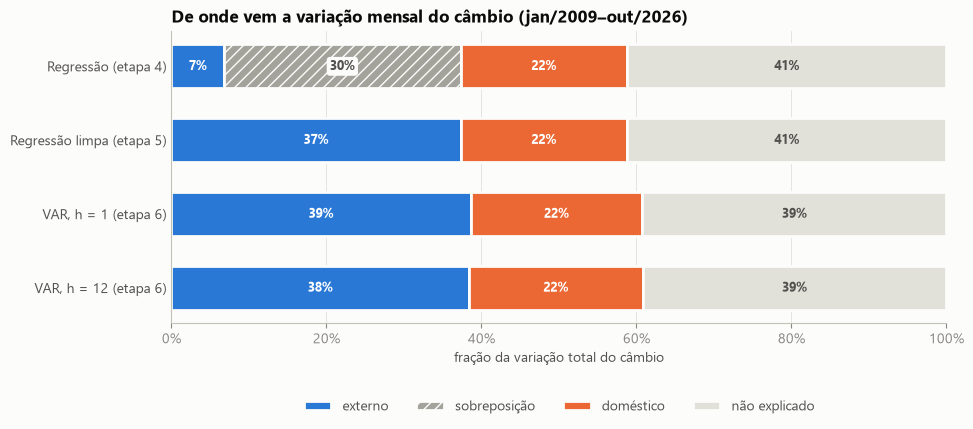

In [4]:
segmentos = [
    ("externo", AZUL, None),
    ("sobreposição", CINZA_MEDIO, "///"),
    ("doméstico", LARANJA, None),
    ("não explicado", CINZA_CLARO, None),
]
ordem = painel_a.index[::-1]   # etapa 4 no topo

fig, ax = plt.subplots(figsize=(10, 3.8))
esquerda = pd.Series(0.0, index=ordem)
for nome, cor, hachura in segmentos:
    largura = painel_a.loc[ordem, nome]
    ax.barh(ordem, largura, left=esquerda, height=0.6, color=cor, hatch=hachura,
            edgecolor=FUNDO, linewidth=2, label=nome)
    for metodo in ordem:   # rótulo só em segmentos largos o bastante
        if largura[metodo] >= 0.06:
            cor_txt = "white" if nome in ("externo", "doméstico") else TINTA_2
            caixa = dict(boxstyle="round,pad=0.25", fc=FUNDO, ec="none") if hachura else None
            ax.text(esquerda[metodo] + largura[metodo] / 2, metodo, f"{largura[metodo]:.0%}",
                    ha="center", va="center", fontsize=9, color=cor_txt, fontweight="bold", bbox=caixa)
    esquerda += largura

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=TINTA_2, length=0)
ax.set_title("De onde vem a variação mensal do câmbio (jan/2009–out/2026)")
ax.set_xlabel("fração da variação total do câmbio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
salvar(fig, "1_comparacao_metodos")

## Gráfico 2 — Quais choques importam (FEVD, h = 12)

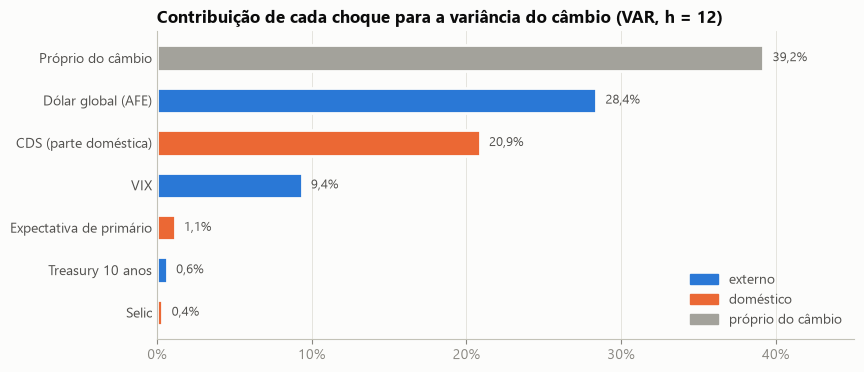

In [5]:
nomes = {
    "d_ust10": "Treasury 10 anos", "dl_vix": "VIX", "dl_dolar": "Dólar global (AFE)",
    "d_selic": "Selic", "d_primario": "Expectativa de primário", "dl_cds": "CDS (parte doméstica)",
    "dl_cambio": "Próprio do câmbio",
}
bloco_cor = {"d_ust10": AZUL, "dl_vix": AZUL, "dl_dolar": AZUL,
             "d_selic": LARANJA, "d_primario": LARANJA, "dl_cds": LARANJA, "dl_cambio": CINZA_MEDIO}

contrib = fevd_var.loc["h=12"].sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([nomes[v] for v in contrib.index], contrib.values,
        color=[bloco_cor[v] for v in contrib.index], height=0.6, edgecolor=FUNDO, linewidth=2)
for i, valor in enumerate(contrib.values):
    ax.text(valor + 0.006, i, f"{valor:.1%}".replace(".", ","), va="center", fontsize=9, color=TINTA_2)

ax.set_xlim(0, contrib.max() * 1.15)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=TINTA_2, length=0)
ax.set_title("Contribuição de cada choque para a variância do câmbio (VAR, h = 12)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="externo"), Patch(color=LARANJA, label="doméstico"),
                   Patch(color=CINZA_MEDIO, label="próprio do câmbio")],
          loc="lower right")
salvar(fig, "2_contribuicao_por_variavel")

## Gráfico 3 — Peso externo ao longo do tempo

Cada ponto = **fim** de uma janela. Linhas sólidas cinzas = episódio **entra** na janela de 60 meses;
pontilhadas = episódio **sai** dela (60 meses depois).

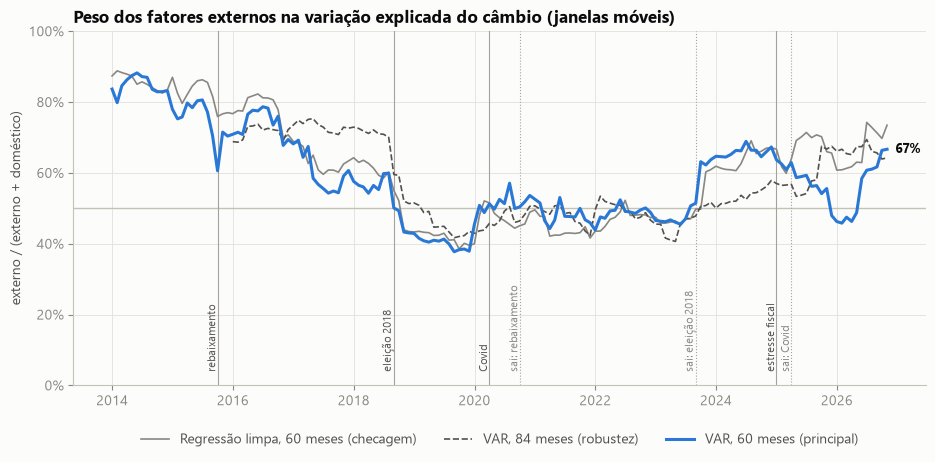

In [6]:
episodios = {"2015-09-30": "rebaixamento", "2018-08-31": "eleição 2018",
             "2020-03-31": "Covid", "2024-12-31": "estresse fiscal"}

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axhline(0.5, color="#c3c2b7", lw=1)
for data, nome in episodios.items():
    entra = pd.Timestamp(data)
    sai = entra + pd.DateOffset(months=60)
    ax.axvline(entra, color=CINZA_MEDIO, lw=0.8)
    ax.text(entra, 0.03, f" {nome}", rotation=90, fontsize=8, color=TINTA_2, va="bottom", ha="right")
    if sai <= var60.index[-1]:
        ax.axvline(sai, color=CINZA_MEDIO, lw=0.8, ls=":")
        ax.text(sai, 0.03, f" sai: {nome}", rotation=90, fontsize=8, color=MUDO, va="bottom", ha="right")

ax.plot(reg60.index, reg60["externo / explicado"], color=MUDO, lw=1.2, label="Regressão limpa, 60 meses (checagem)")
ax.plot(var84.index, var84["externo / explicado"], color=TINTA_2, lw=1.2, ls="--", label="VAR, 84 meses (robustez)")
ax.plot(var60.index, var60["externo / explicado"], color=AZUL, lw=2.2, label="VAR, 60 meses (principal)")

ultimo = var60["externo / explicado"].iloc[-1]
ax.annotate(f"{ultimo:.0%}", (var60.index[-1], ultimo), xytext=(6, 0), textcoords="offset points",
            va="center", fontsize=9, color=TINTA, fontweight="bold")

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Peso dos fatores externos na variação explicada do câmbio (janelas móveis)")
ax.set_ylabel("externo / (externo + doméstico)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
salvar(fig, "3_peso_externo_no_tempo")

## Gráfico 4 — Composição completa ao longo do tempo (VAR, 60 meses)

Altura de cada faixa = peso daquela fonte; o topo da faixa laranja = quanto o modelo explica.

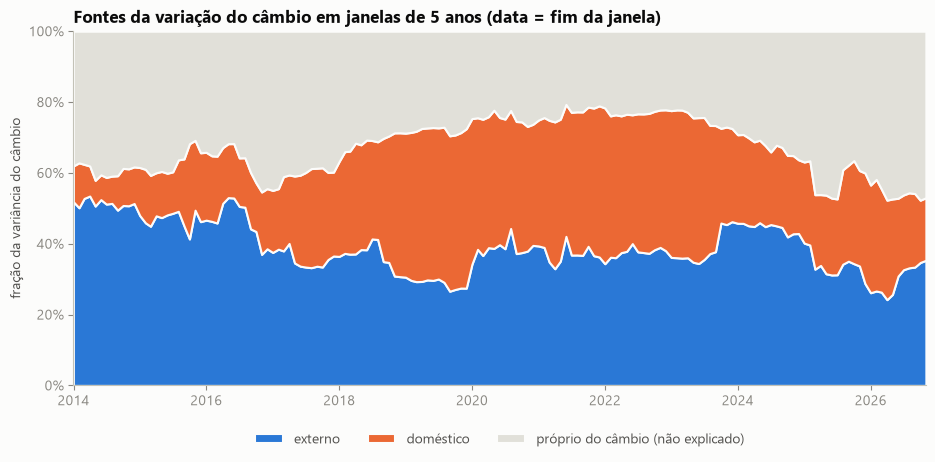

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.stackplot(var60.index, var60["externo"], var60["doméstico"], var60["próprio"],
             colors=[AZUL, LARANJA, CINZA_CLARO], edgecolor=FUNDO, linewidth=1.5,
             labels=["externo", "doméstico", "próprio do câmbio (não explicado)"])
ax.set_ylim(0, 1)
ax.set_xlim(var60.index[0], var60.index[-1])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(False)
ax.set_title("Fontes da variação do câmbio em janelas de 5 anos (data = fim da janela)")
ax.set_ylabel("fração da variância do câmbio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
salvar(fig, "4_composicao_no_tempo")

## Gráfico 5 — O risco-país decomposto

Variação acumulada do ln(CDS) desde dez/2008, separada em parte prevista pelas externas (contágio
global) e resíduo (parte brasileira). A linha laranja termina em zero por construção
(resíduos do MQO somam zero) — leia os **movimentos**, não o nível final.

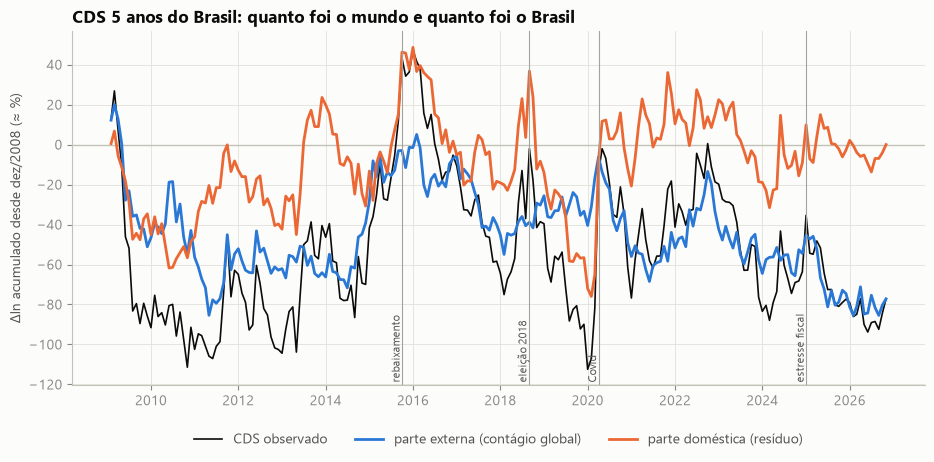

In [8]:
cds_dom = limpas["dl_cds_dom"]
cds_ext = variacoes["dl_cds"] - cds_dom

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axhline(0, color="#c3c2b7", lw=1)
ax.plot(variacoes["dl_cds"].cumsum(), color=TINTA, lw=1.2, label="CDS observado")
ax.plot(cds_ext.cumsum(), color=AZUL, lw=2, label="parte externa (contágio global)")
ax.plot(cds_dom.cumsum(), color=LARANJA, lw=2, label="parte doméstica (resíduo)")
for data, nome in episodios.items():
    ax.axvline(pd.Timestamp(data), color=CINZA_MEDIO, lw=0.8)
    ax.text(pd.Timestamp(data), ax.get_ylim()[0], f" {nome}", rotation=90, fontsize=8,
            color=TINTA_2, va="bottom", ha="right")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("CDS 5 anos do Brasil: quanto foi o mundo e quanto foi o Brasil")
ax.set_ylabel("Δln acumulado desde dez/2008 (≈ %)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
salvar(fig, "5_cds_decomposto")

## Painel B — peso externo por fase (janelas de 60 meses)

Fases identificadas na etapa 7, pela **data de fim** da janela.

In [9]:
fases = {
    "1. dez/2013–dez/2015 (pós-2008, liquidez global)": ("2013-12", "2015-12"),
    "2. jan/2016–jul/2018 (crise doméstica entrando)":  ("2016-01", "2018-07"),
    "3. ago/2018–ago/2023 (domínio doméstico)":         ("2018-08", "2023-08"),
    "4. set/2023–out/2026 (crises de 2015–18 saem)":    ("2023-09", "2026-10"),
}
painel_b = pd.DataFrame({
    nome: {
        "externo": var60.loc[ini:fim, "externo"].mean(),
        "doméstico": var60.loc[ini:fim, "doméstico"].mean(),
        "próprio do câmbio": var60.loc[ini:fim, "próprio"].mean(),
        "externo / explicado": var60.loc[ini:fim, "externo / explicado"].mean(),
        "nº de janelas": len(var60.loc[ini:fim]),
    }
    for nome, (ini, fim) in fases.items()
}).T
painel_b.round(3)

,externo,doméstico,próprio do câmbio,externo / explicado,nº de janelas
"1. dez/2013–dez/2015 (pós-2008, liquidez global)",0.490,0.129,0.381,0.794,25.0
2. jan/2016–jul/2018 (crise doméstica entrando),0.403,0.223,0.374,0.644,31.0
3. ago/2018–ago/2023 (domínio doméstico),0.354,0.397,0.250,0.471,61.0
4. set/2023–out/2026 (crises de 2015–18 saem),0.371,0.241,0.388,0.602,38.0


## Painel C — decisões metodológicas

In [10]:
painel_c = pd.DataFrame([
    ("Variável dependente", "PTAX de venda (SGS 1), 100·Δln, mensal (último dia útil)"),
    ("Externas", "Treasury 10a (DGS10, Δ), VIX (VIXCLS, 100·Δln), dólar vs. economias avançadas (DTWEXAFEGS, 100·Δln)"),
    ("Domésticas", "Meta Selic (SGS 432, Δ), CDS 5a Investing.com (100·Δln), Focus resultado primário em horizonte fixo de 12m (Δ)"),
    ("Amostra", "jan/2009–out/2026 (214 meses); início definido pelo CDS sem preço velho"),
    ("Estacionariedade", "ADF e KPSS: todas as variações estacionárias"),
    ("Regressão", "MQO padronizado, erros-padrão HAC (Newey-West, 4 defasagens); dummy abr/2020 testada e descartada"),
    ("Limpeza", "Domésticas regredidas nas 3 externas; resíduo = componente doméstico"),
    ("VAR", "p = 1 (BIC escolheu 0; Portmanteau p = 0,26); estável; Granger doméstico→externo não rejeitado (p = 0,18)"),
    ("Identificação", "Cholesky: Treasury → VIX → dólar → Selic → primário → CDS → câmbio"),
    ("FEVD", "Horizontes 1, 3, 6, 12 meses"),
    ("Janelas móveis", "60 meses (principal), 84 meses (robustez), p = 1 fixo, data = fim da janela"),
    ("Limitações", "Exclui a crise de 2008; commodities fora do modelo; sem intervalos de confiança nas janelas"),
], columns=["Item", "Escolha"]).set_index("Item")
painel_c

,Escolha
Item,
Variável dependente,"PTAX de venda (SGS 1), 100·Δln, mensal (último..."
Externas,"Treasury 10a (DGS10, Δ), VIX (VIXCLS, 100·Δln)..."
Domésticas,"Meta Selic (SGS 432, Δ), CDS 5a Investing.com ..."
Amostra,jan/2009–out/2026 (214 meses); início definido...
Estacionariedade,ADF e KPSS: todas as variações estacionárias
Regressão,"MQO padronizado, erros-padrão HAC (Newey-West,..."
Limpeza,Domésticas regredidas nas 3 externas; resíduo ...
VAR,"p = 1 (BIC escolheu 0; Portmanteau p = 0,26); ..."
Identificação,Cholesky: Treasury → VIX → dólar → Selic → pri...


In [11]:
with pd.ExcelWriter(RES / "resumo.xlsx") as excel:
    painel_a.round(3).to_excel(excel, sheet_name="A - amostra completa")
    painel_b.round(3).to_excel(excel, sheet_name="B - fases")
    painel_c.to_excel(excel, sheet_name="C - decisões")

print("Figuras:", sorted(p.name for p in FIG.glob("*.png")))
print("Tabela:", RES / "resumo.xlsx")

Figuras: ['1_comparacao_metodos.png', '2_contribuicao_por_variavel.png', '3_peso_externo_no_tempo.png', '4_composicao_no_tempo.png', '5_cds_decomposto.png']
Tabela: resultados\resumo.xlsx
